<center>
    <h2>Master 2</h2>
    <h5 style="margin-top: 5px">Sciences de l’Océan, de l’Atmosphère et du Climat</h5>
    <h1>TP - Simulations climatiques</h1>
  <br>
    <strong>Contact:</strong> isaline.bossert@meteo.fr / romain.torres4@gmail.com / gwenael.martin@meteo.fr

</center>


<div style="padding: 1rem; background-color: #d1ecf1; border: 1px solid #bee5eb; border-radius: 4px; margin: 1rem 0;">
  <strong>💡 Instructions</strong> 
    
Ce notebook est à <i>compléter</i> avec vos réponses aux questions posées et à <i>envoyer</i> par mail au plus tard <u>une semaine après la dernière séance de TP</u>. Merci de renommer le notebook pour y incorporer vos noms de famille (ex: TP-Climat-2026-Nom1_Nom2_Nom3.ipynb)
  - une attention particulière doit être donnée aux <b>figures</b> (clareté, titre, axes, légendes, etc..) 
  - les analyses portent sur vos <b>connaissances théoriques</b> en lien avec le cours "Système Climatique" (J. Cattiaux) sont attendues
  - la <b>curiosité scientifique</b> est bien sûre encouragée: même si les questions sont là pour aiguiller le TP, n'hésitez pas à demander des clarifications où d'éventuelles pistes d'analyses supplémentaires ;)
    

⚠️ Lors de la dernière séance, chaque groupe présentera son notebook (sujet + analyses effectuées):
  - durée max de 15 minutes de restitution qui doit être <b>claire</b> et <b>synthétique</b>. Il n'est pas nécessaire de créer un support de présentation particulier.
  - la restitution est suivie d'un <b>tour de questions</b> de la part des élèves puis des enseignantes pour vérifier les notions

<center>
        <h1>Sujet 1: Analyse de la réponse climatique à une <br> augmentation brutale de CO$_2$ dans l'atmosphère</h1>
  <br>
    <strong>Main topics covered here:</strong>
    <br>
    Earth energy balance models (c.f. Cours 2)
    <br>
    Radiative forcings and climate feedbacks (c.f. Cours 3) 

</center>

## Introduction

Human activities generate a _radiative forcing_ on the climate system, mostly by increasing greenhouse gas concentration in the atmopshere.
A radiative forcing applied to the climate system must result in a climate change which tends to counteract the forcing.
Understanding how the Earth's climate changes to greenhouse gas forcing is essential for climate adaptation and mitigation.

In order to study the climate response to a fixed radiative forcing, an idealized emission scenario can be used in which the atmospheric CO$_2$ concentration is suddenly quadrupled and then kept constant for 150 years, the so-called _abrupt-4xCO2_ experiment ([Fig. 1](#tp1-fig1)). 
This step-like changes in CO$_2$ concentration may not be realistic, but has the advantage to keep radiative forcing constant, hence revealing fundamental behavior of the climate system. 
Climate change given by the model is calculated by subtracting the results of the its own control experiment, which has constant atmospheric composition and a steady-state climate. 
A common practice for the control experiment is to run the same model under constant pre-industrial CO$_2$ concentration (around 284 ppm), the so-called _piControl_ experiment.

In this notebook, you will analyze the climate response to quadrupling CO$_2$ concentration using outputs from the CNRM-CM6-1 model ([Voldoire et al., (2019)](https://doi.org/10.1029/2019MS001683). CNRM‐CM6‐1 is a fully coupled atmosphere‐ocean general circulation model of sixth generation jointly developed by Centre National de Recherches Météorologiques (CNRM) and Cerfacs for the sixth phase of the Coupled Model Intercomparison Project 6 (CMIP6).
In addition to the atmosphere and ocean circulations, it includes several climate components such as land surface, sea-ice and river routing ([Fig. 2](#tp1-fig2)). The model can be run in greenhouse gases concentration mode, allowing to fix atmospheric CO$_2$ levels. 

In particular, you will:
  - use model of Earth energy equation to show the differences between an equilibrated and non-equilibrated climate
  - compute the climate sensitivity, which measures the strength of the temperature response to radiative forcing
  - highlight climate feedbacks
  - discuss your results using other climate models


<br>

<div align="center">
    <div id="tp1-fig1" style="width: 550px; float: left">
        <img src="../figures/Zhang_and_Chen-2024-CO2_in_CMIP_experiments.png" alt="drawing" width="500"/>
    </div>
    <div style="width: 300px; float right">
        <img src="../figures/Voldoire-2019-CNRM-CM6-1.png" alt="drawing" width="400"/>
    </div>
    <br>
    <div>
    <div id="tp1-fig2" style="width: 550px; float: left">
    <b>Fig. 1. </b>Changes in CO2 concentration in different climate model experiments. The large dot on each line indicates the year of maximum concentration. For the abrupt quadrupling of CO2 experiment (abrupt-4xCO2), the CO2 concentration maximum year is labeled as the first year of the 150 year period between 1850 and 1999. Taken from <a href="https://doi.org/10.1007/s00382-024-07397-7">Zhang and Chen (2024)</a>.
    </div>
    <div style="width: 300px; float right">
    <b>Fig. 2. </b>CNRM-CM6-1 schematic and all its components. Taken from <a href="https://doi.org/10.1029/2019MS001683">Voldoire et al. (2019)</a>.
    </div>
    </div>
</div>

<br><br><br><br>

## Load Python modules and simulation outputs

Along this notebook, Python codes are used to analyse model outputs.
You first need to import and load required modules:

In [1]:
# manipulate file and data
import csv
import os
import numpy  as np
import xarray as xr

# plotting
import matplotlib
import matplotlib.pyplot as plt

The code below loads results from CNRM-CM6-1 model for both its _piControl_ and _abrupt-4xCO2_ experiments.

In [27]:
# initialize empty dict to store variables
piCtrl = dict()
abrupt = dict()

# load netCDF (.nc) files using xarray
for f in os.listdir("../data/CMIP6"):
    var   = f.split('_')[0]
    model = f.split('_')[2]
    expe  = f.split('_')[3]
    
    # select only CNRM-CM6-1 model
    if model == 'CNRM-CM6-1':
        ds = xr.load_dataset(os.path.join("../data/CMIP6", f), use_cftime=True)
        
        if expe == 'piControl':
            piCtrl[var]      = ds[list(ds.variables)[-1]]
            piCtrl[var].name = var
        elif expe == 'abrupt-4xCO2':
            abrupt[var]      = ds[list(ds.variables)[-1]]
            abrupt[var].name = var
            
print("Variables loaded in piCtrl: \n", list(piCtrl.keys()))
print("")
print("Variables loaded in abrupt: \n", list(abrupt.keys())) 

Variables loaded in piCtrl: 
 ['rsutcs', 'ts', 'snws', 'siextentn', 'snwn', 'siextents', 'lain', 'rsdt', 'rsut', 'rlut', 'lais', 'rlutcs']

Variables loaded in abrupt: 
 ['rsutcs', 'siextentn', 'snwn', 'rsut', 'siextents', 'lain', 'ts', 'rlutcs', 'rsdt', 'snws', 'rlut', 'lais']


| Variables |    Description                                               || Variables |    Description                                               ||
|:---------:|:------------------------------------------------------------:||:---------:|:------------------------------------------------------------:||
|  ts       |    surface temperature                                       || siextentn | sea ice extent in the northern hemisphere                ||
| rsdt      | top-of-atmosphere shortwave incoming flux                    || siextents | sea ice extent in the southern hemisphere                ||
| rlut      | top-of-atmosphere shortwave outgoing flux                    || snwn      | surface snow amount in the northern hemisphere                ||
| rsut      | top-of-atmosphere longwave  outgling flux                    || snws      | surface snow amount in the southern hemisphere                ||
| rlutcs    | top-of-atmosphere longtwave outgoing flux assuming clear sky || lain      | leaf area index averaged in the northern hemisphere         ||
| rsutcs    | top-of-atmosphere shortwave outgling flux assuming clear sky || lais      | leaf area index averaged in the southern hemisphere         ||

Here we have used the python module _xarray_ to load dataset. Each variable are store in python dictionnaries `piCtrl` and `abrupt` for the _piControl_ and _abrupt-4xCO2_ experiments, respectively.
You can access to the data, by using the variable name:

```python
    piCtrl['ts']          # this return an xarray.DataArray object
    piCtrl['ts'].data     # this return an numpy.array object
    piCtrl['ts']['time']  # this return the 'time' coordinate for the variable 'ts'
```

Both the _piControl_ and the _abrupt-4xCO2_ experiments start in january 1850 and last for 500 years and 150 years, respectively. However, it should be noted that since these experiments are only idealized simulation and do not attempt to reproduce true time periods.

Note that experiments have monthly ouput, and therefore exhibit seasonal cycle. In order to filter this, it is preferable to use yearly average that can be computed using [xarray groupby](https://docs.xarray.dev/en/stable/generated/xarray.DataArray.groupby.html) function:

```python
    # compute yearly averaged surface temperature
    ts = piCtrl['ts'].groupby('time.year').mean()
```

<a id="section-1"></a>
## 1. Earth energy balance

General circulaion models, such as CNRM-CM6-1, solve primitive equations to simulate evolution of the atmosphere and ocean circulations in a 3D space ($x, y, z$).
As a result, they allow to study the energy repartition in the horizontal ($x$, $y$) as well as in different fluid layers ($z$), at the expense of complex and large output data files. 

In this section, the problem dimension is reduced by using global averaged variable of CNRM-CM6-1, which is equivalent to build a simple 0D energy balance model (EBM) that match the simulation done using a more complex general circulation model.

#### Question 1: 

* _After having define the Earth climate system, write its energy budget (0D) and add an illustration of the model_
* _How is defined the equilibrium ?_

__Help__: you can insert Latex math code using '$' symbols and insert image using html code:
```html
<img src="image.png" alt="drawing" width="400"/>
```


<font color="blue">

We can define the Earth climate system as the solid Earth plus liquid and solid waters (ocean, rivers, lake and cryosphere) and the atmosphere, which encompasses the other components. The energy budget is written by summing energy inputs and outputs at the system boundary, which is here the top of the atmopshere: 
    $$\Delta R = \left(1-\alpha\right)S_0/4 - \sigma T_e^4 \,$$
    
At the equilibrium, $\Delta R = 0$. But this equilibrium can be perturbed by external forcings $\text{F}$ of different type (solar, greenhouse gases, aerosols and surface).
    
<img src="../figures/Simplified_Energy_Balance_Model.png" alt="drawing" width="500"/>

 - [ ] alternative avec bilan d'énergie en surface ? vérifier qu'on ait bien les variables sur ESGF !
</font>

#### Question 2: 

* _Compute the energy budget in piControl experiment_
* _Is the simulated climate equilibrated ?_


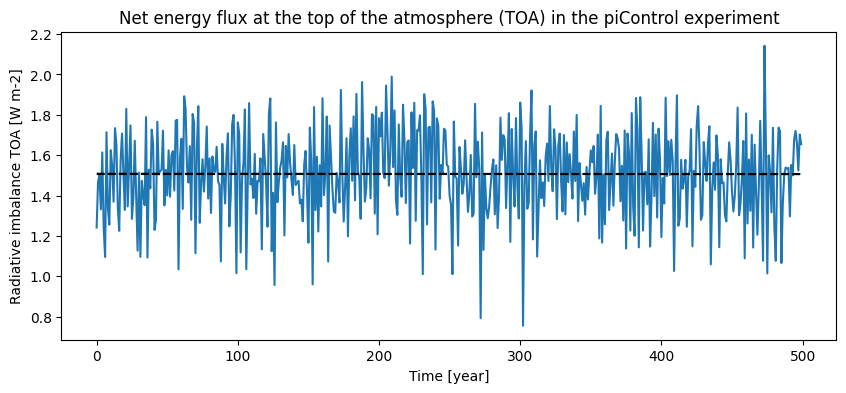

In [3]:
dR_piCtrl = piCtrl['rsdt'] - piCtrl['rsut'] - piCtrl['rlut']
dR_piCtrl = dR_piCtrl.groupby('time.year').mean()

# plot
fig, ax = plt.subplots(1,1, figsize=(10, 4))

ax.plot( np.arange(len(dR_piCtrl['year'])), dR_piCtrl,                          c='tab:blue')

# compute linear trend
x     = np.vstack([np.arange(len(dR_piCtrl['year'])), np.ones(len(dR_piCtrl['year']))]).T
c, y0 = np.linalg.lstsq(x, dR_piCtrl, rcond=-1)[0]

ax.plot( np.arange(len(dR_piCtrl['year'])), c * x + y0, ls='--', c='k')

# axe properties
ax.set_xlabel('Time [year]')
ax.set_ylabel('Radiative imbalance TOA [W m-2]')

_ = ax.set_title("Net energy flux at the top of the atmosphere (TOA) in the piControl experiment")

<font color="blue">

The model is not perfectly equilibrated since $\Delta R > 0$ (the system gains energy). 
Its a common problem encountered on most global circulation model. 
However, the energy imbalance is stable and could be removed from the _abrupt-4xCO2_ experiment.
    
</font>

#### Question 3: 

* _Compute the budget in abrupt-4xCO2 experiment_
* _Is the simulated climate equilibrated ?_


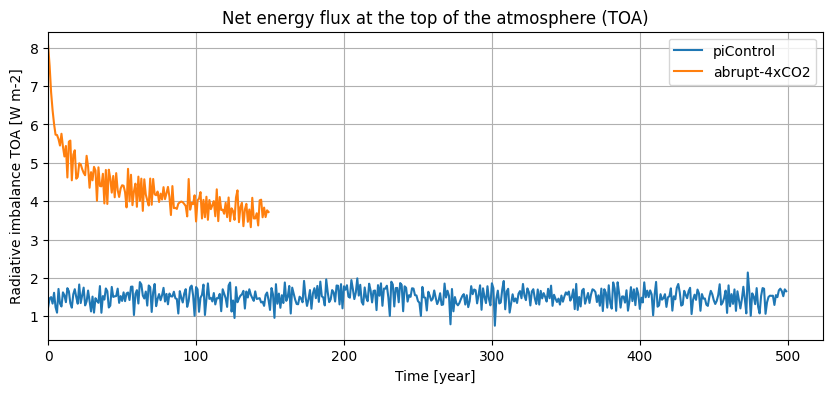

In [4]:
dR_abrupt = abrupt['rsdt'] - abrupt['rsut'] - abrupt['rlut']
dR_abrupt = dR_abrupt.groupby('time.year').mean()

# plot
fig, ax = plt.subplots(1,1, figsize=(10, 4))

ax.plot( np.arange(len(dR_piCtrl['year'])), dR_piCtrl, c='tab:blue',   label='piControl')
ax.plot( np.arange(len(dR_abrupt['year'])), dR_abrupt, c='tab:orange', label='abrupt-4xCO2')

ax.legend()
ax.grid(True)

ax.set_xlim((0, None))

ax.set_xlabel('Time [year]')
ax.set_ylabel('Radiative imbalance TOA [W m-2]')

_ = ax.set_title("Net energy flux at the top of the atmosphere (TOA)")

<font color="blue">

The model is not equilibrated ($\Delta R > 0$, meaning that the system gains energy). 
It is, however, important to note that we do not expect that $\Delta_R$ goes to zero even after running the model for a long time. Indeed, the model will tend to reach the average imbalance computed in the _piControl_ simulation (around 1.5 W m-2).
    
At the begining of the _abrupt-4xCO2_ simulation, the TOA energy imbalance is high (around +8 W.m-2) due to the suddenly increase (four times !) of CO$_2$ concentration in the atmosphere. It then decreases exponentially, but has not reached the _piControl_ value after 150 years, showing that there are still ongoing changes in the system (e.g. its temperature) to adapt to this forcing. 
    
</font>

#### Question 4: 

We will now analyze variable anomalies (by removing _piControl_ signals from the variable computed in the _abrupt-4xCO2_ simulation).

* _Plot anomalies of surface temperature and net top of atmosphere energy imbalance. Explain the evolution in respect to the energy input._
* _Compute the radiative forcing implies by having quadruple CO$_2$ concentration. Compare your value to the formulation adopted since the third IPCC report [(Ramaswamy et al., 2001)](https://www.ipcc.ch/reports/?rp=ar3):_

$$ F_{\text{CO}_2}= 5.35 \times \ln\left(\frac{\text{CO}_2(t)}{\text{CO}_2(t=0)}\right)$$

__help:__ think about the linearized climate response ($\Delta T$) to a radiative forcing:

$$ \Delta R = F - \lambda \Delta T$$


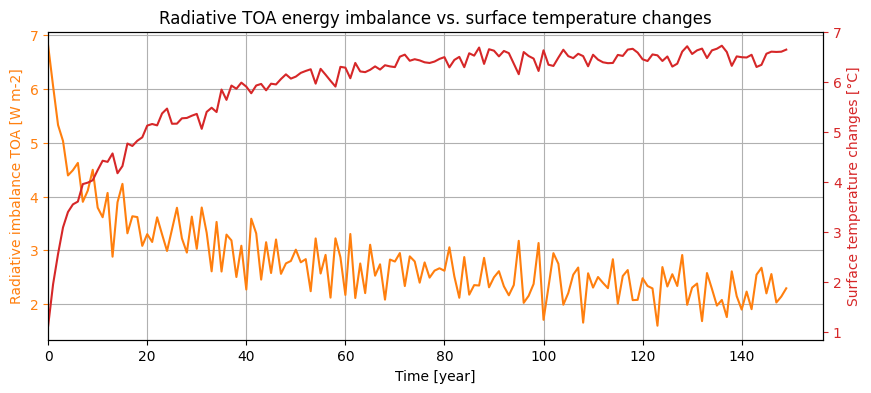

In [5]:
# plot temperature and energy anomalies
fig, ax = plt.subplots(1,1, figsize=(10, 4))

dT      = (abrupt['ts'] - piCtrl['ts']).groupby('time.year').mean()
dR      =  dR_abrupt    - dR_piCtrl

# dR
ax.plot( np.arange(len(dR['year'])), dR, c='tab:orange')

ax2 = ax.twinx()
ax2.plot( np.arange(len(dT['year'])), dT, c='tab:red')

ax.grid(True)
ax.set_xlim((0, None))
ax.set_xlabel('Time [year]')
ax.set_ylabel('Radiative imbalance TOA [W m-2]',   color='tab:orange')
ax2.set_ylabel('Surface temperature changes [°C]', color='tab:red')

ax.tick_params(axis='y' , colors='tab:orange')
ax2.tick_params(axis='y', colors='tab:red')


_ = ax.set_title("Radiative TOA energy imbalance vs. surface temperature changes")

In [6]:
# Compute CO2 forcing
net_dRa = (abrupt['rsdt'] - abrupt['rsut'] - abrupt['rlut'])
net_dRp = (piCtrl['rsdt'] - piCtrl['rsut'] - piCtrl['rlut'])

F_CO2   = (net_dRa - net_dRp)[0]
F_CO2an = 5.35 * np.log(4)

print("TOA energy imbalance during the first month of the abrupt-4x experiment: {:.2f} W m-2".format(float(F_CO2)))
print("Analytical CO2 forcing after quadrupling atmospheric concentration: {:.2f} W m-2".format(F_CO2an))

TOA energy imbalance during the first month of the abrupt-4x experiment: 7.15 W m-2
Analytical CO2 forcing after quadrupling atmospheric concentration: 7.42 W m-2


<font color="blue">

**The surface temperature increases in the _abrupt-4xCO2_ experiment** following an exponential growth, in a similar but opposite sign than the TOA energy imbalance.   

This was expected due to our understanding on how the system responds to increasing greenhouse gases in the atmosphere:
  - the absorptivity of the atmosphere is close to 1, i.e., almost all surface radiation is absorbed. Increasing the amount of greenhouse gases therefore has only a relatively marginal effect on absorptivity: it is only increased at wavelengths where opacity is not already total. 
  - however, the addition of greenhouse gases have an impact on the amount of radiation emitted at the top of the atmosphere ($\sigma T_e^4$). Due to the negative temperature gradient in the troposphere, an increase of CO$_2$ leads to a reduction of $T_e$ (the atmosphere layer that emit longwave is higher in altitude). This results in a gain of energy in the climate system warming the troposphere where the temperature gradient is shifted to reach a new equilibrium (leading to an increase of the surface temperature).

    
The radiative forcing $F$ is constant in the _abrupt-4xCO2_ experiment and can be decuced at the begining of the simulation for $\Delta T = 0$, where the net imbalance $\Delta R = F$. Using the first month of the simulation, the forcing is about 7.15 W m-2, close to the analytical value (7.42 W m-2).
</font>

#### Question 5: 

* _Present a plot that decompose the energy budget and try to describe and interpret the results._


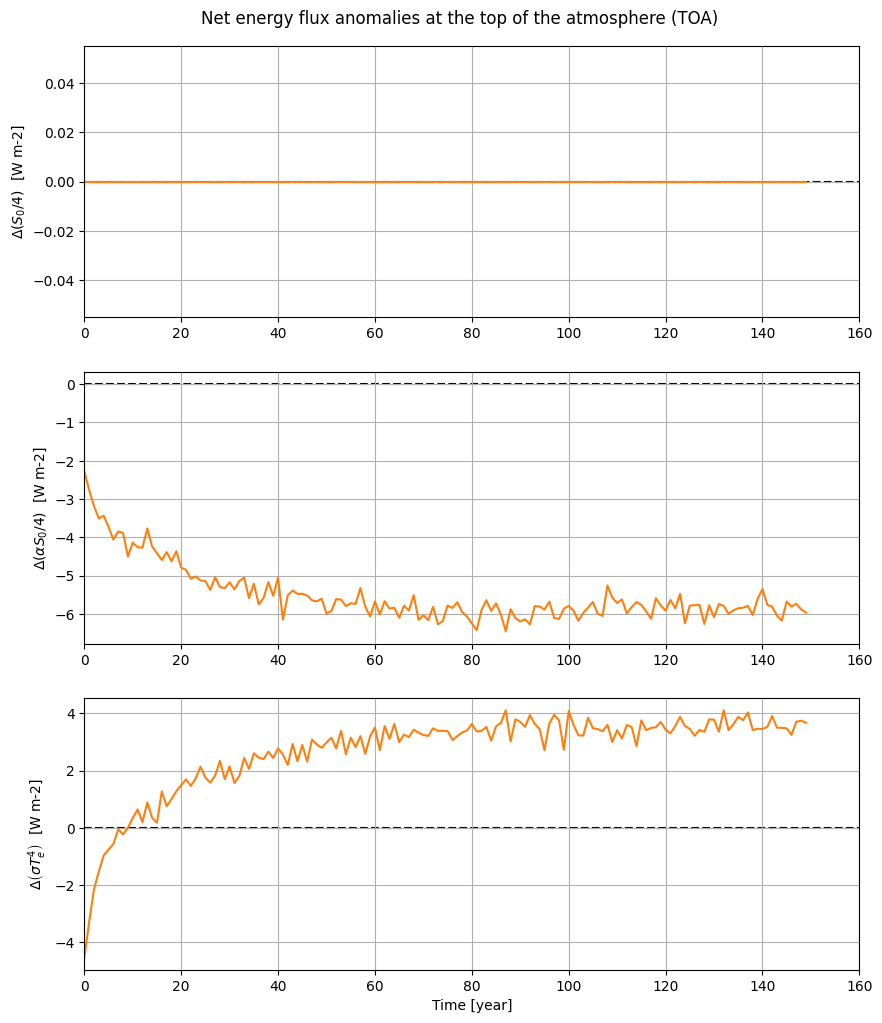

In [7]:
# plot temperature and energy anomalies
fig, axes = plt.subplots(3,1, figsize=(10, 12))

dRLUT     = (abrupt['rlut'] - piCtrl['rlut']).groupby('time.year').mean()
dRSUT     = (abrupt['rsut'] - piCtrl['rsut']).groupby('time.year').mean()
dRSDT     = (abrupt['rsdt'] - piCtrl['rsdt']).groupby('time.year').mean()

# dR
axes[0].plot( np.arange(len(dRSDT['year'])), dRSDT, c='tab:orange')
axes[1].plot( np.arange(len(dRSUT['year'])), dRSUT, c='tab:orange')
axes[2].plot( np.arange(len(dRLUT['year'])), dRLUT, c='tab:orange')

axes[0].set_ylabel(r'$\Delta \left(S_0/4\right)$  [W m-2]')
axes[1].set_ylabel(r'$\Delta \left(\alpha S_0/4\right)$  [W m-2]')
axes[2].set_ylabel(r'$\Delta \left(\sigma T_e^4\right)$  [W m-2]')

for ax in axes:
    ax.hlines(0,0,160, color="k", ls="--", alpha=1, zorder=-10)
    ax.grid(True)
    ax.set_xlim((0, 160))
    
    if ax == axes[-1]:
        ax.set_xlabel('Time [year]')

_ = fig.suptitle("Net energy flux anomalies at the top of the atmosphere (TOA)", y=0.91)

<font color="blue">

- **The shortwave incoming radiation ($S_0/4$) is unchanged after quadrupling CO$_2$ concentration.**

  - The incoming shortwave radiation (at the top of the atmosphere) is directly related to the solar irradiance and thus to the solar constant $S_0$. Its amplitude is mostly related to sun activity and to the Earth orbit (to the Sun-Earth distance and angle). Increasing the greenhouse concentration in the atmophere has no impact on this, and thus remains constant between _piControl_ and _abrupt-4xCO2_ experiments.
    
    
- **The shortwave reflection ($\alpha S_0/4$) is reduced**. 

  - Since $S_0/4$ is kept constant, changes in shortwave upward flux have to comes from a change in albedo $\alpha$. Since the budget is computed at the top of the atmosphere, change in $\alpha$ could be due to a change in surface properties (e.g. snow and ice melting due to the surface warming) or to changes in cloud reflection. 
  - Regarding, $\alpha$, changes in Earth surface temperature could lead to a decrease of the Earth's albedo, which in turn reflect less energy out of the system. As a consequence, more solar radiation is absorbed leading to further warming of the surface temperature. This illustrates a _positive feedback_ (CO$_2$ forcings $F \Rightarrow \Delta T \uparrow \Rightarrow \alpha\downarrow \Rightarrow \Delta T \uparrow$)
  - The impact of the clouds is less direct since clouds can reflect incoming solar flux as well as the energy flux reflected by Earth surfaces, so that it is almost impossible to conclude without a detailed investigation of the model outputs and their spatial variation. 
 
    However, these two hypotheses are only speculative and a detailed analysis of individual term is necessary to uderstand what really cause changes in $\alpha$.

    
- **The longwave radiation ($\sigma T_e^4$) at the top-of-atmosphere is immediately reduced** (~4 W/m2) when CO$_2$ concentration is suddenly quadrupled, and then **increases** during the simulation. The time evolution looks similar to that of surface temperature. It is important to note that this flux becomes larger in _abrupt-4xCO2_ than _piControl_ after ten years.  
   
  - This behaviour was expected as discussed in the temperature figure. Indeed, changes in the atmosphere composition lead to a higher emission altitude, which combined with the negative temperature gradient in the troposphere, reduce the temperature of emission $T_e$. Then the troposphere adjust its temperature to a new equilibrium, increasing the temperature profile in all the troposphere.
    This illustrates a transitory behaviour of the system which tends to reach a new equilibrium.
    
</font>

<a id="section-2"></a>
## 2. Climate sensitivity


In the previous section, we have estimate the energy imbalance within the CNRM-CM6-1 climate model and how the simulated climate have changed (its surface temperature $\Delta T$) in response to a fixed radiative forcing.

Here, we will use the concept of climate sensitivity, also called Equilibrium Climate Sensitivity (ECS), to quantify the magnitude of the response. The ECS is a useful metric to compare climate models or different forcing experiments (e.g. aerosols, greenhouse gases, solar variability).

We first recall that the Earth surface temperature change ($\Delta T$) can be linearized and written as:
$$ \Delta R = F - \lambda \Delta T$$
where $\Delta R$ is the net resulting energy flux (at the top of the atmosphere) and $F$ the radiative forcing (i.e. a perturbation from the energy budget at the equilibrium). 

The surface temperature will change until a new equilibrium is reached when $\Delta R = 0$, leading to:
$$ \left(\Delta T\right)_\text{eq} = F / |\lambda|$$

Here, the parameter $\lambda$ is called the climate sensitivity parameter ($<0$) in W.m$^{-2}$.K$^{-1}$. It indicates the strength of the climate system response. It can be computed from a the new equilibrium $\lambda = -F / \left(\Delta T\right)_\text{eq}$, or (if the equilibrium has not been reached) by linear regression of the function $\Delta R = f(\Delta T)$ as proposed by [Gregory et al. (2004)](https://doi.org/10.1029/2003GL018747).

The climate sensitivity (ECS) is the surface temperature change required to reach the equilibrium $\left(\Delta T\right)_\text{eq}$ in °C.

#### Question 6:

* _Plot the transcient response of the abrupt-4xCO2 experiment in the $\{\Delta T, \Delta R\}$_
* _Compute the ECS and the climate sensitivity for CNRM-CM6-1_

__help:__ you can use `plt.scatter` for plotting results.

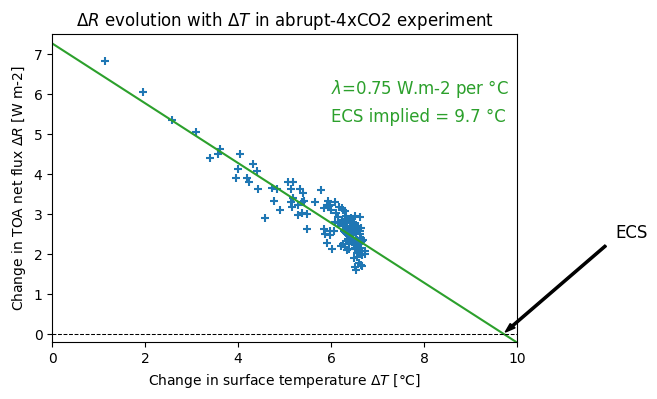

In [8]:
# plot
fig, ax = plt.subplots(1,1, figsize=(6, 4))

ax.scatter( dT, dR, marker='+', c='tab:blue')

# compute linear trend (lambda) and ECS
x         = np.vstack([dT, np.ones(len(dT))]).T
coeff, R0 = np.linalg.lstsq(x, dR, rcond=-1)[0]

ecs       = -R0 / coeff  # dT = -dR/lambda

# plot trend
ax.plot( np.linspace(0, 10, 100), coeff * np.linspace(0, 10, 100) + R0, ls='-', c='tab:green')

# add ECS on plot
ax.arrow(ecs+2.2, 2.2, -2, -2, width=0.05, color='k', clip_on=False)
ax.text(ecs+2.4, 2.4, "ECS", fontsize=12,  c='k')

ax.text(6, 6,   r"$\lambda$={:.2f} W.m-2 per °C".format(-coeff), fontsize=12,  c='tab:green')
ax.text(6, 5.3, r"ECS implied = {:.1f} °C".format(ecs),           fontsize=12,  c='tab:green')

# plot y=0 line
ax.plot( [0, 10], [0, 0], ls='--', lw=0.75, c='k')

# axe properties
ax.set_xlim((0, 10))
ax.set_ylim((-0.2, 7.5))
ax.set_xlabel(r'Change in surface temperature $\Delta T$ [°C]')
ax.set_ylabel(r'Change in TOA net flux $\Delta R$ [W m-2]')

_ = ax.set_title(r"$\Delta R$ evolution with $\Delta T$ in abrupt-4xCO2 experiment")

#### Question 7

* _Use longer 4xCO2 experiments to check the linear regression extrapolation_
* _Based on this analysis, do you think that another method could out-perform a linear fit ? What about the choice of a constant $\lambda$ ?_


- [ ] TODO: give code to load longer (around 2000 years long) 4xCO2 experiment outputs so that the student can replot the diagram and 

In [9]:
# Plot here the diagramm for longer simulation

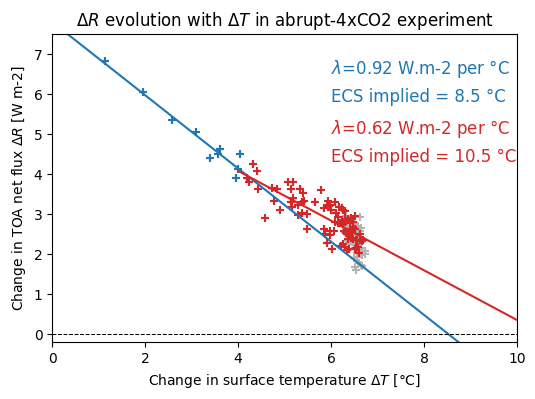

In [16]:
# plot
fig, ax = plt.subplots(1,1, figsize=(6, 4))

ax.scatter( dT, dR, marker='+', color=np.array([.7,.7,.7]))

# compute the method for the 0-10 years period
yi, yf = 0, 10

ax.scatter( dT[yi:yf], dR[yi:yf], marker='+', c='tab:blue')

x         = np.vstack([dT[yi:yf], np.ones(len(dT[yi:yf]))]).T
coeff, R0 = np.linalg.lstsq(x, dR[yi:yf], rcond=-1)[0]
ecs       = -R0 / coeff  # dT = -dR/lambda

ax.plot( np.linspace(0, 10, 100), coeff * np.linspace(0, 10, 100) + R0, ls='-', c='tab:blue')

ax.text(6, 6.5,   r"$\lambda$={:.2f} W.m-2 per °C".format(-coeff), fontsize=12,  c='tab:blue')
ax.text(6, 5.8, r"ECS implied = {:.1f} °C".format(ecs),          fontsize=12,  c='tab:blue')

# compute the method for the 10-100 years period
yi, yf = 10, 100

ax.scatter( dT[yi:yf], dR[yi:yf], marker='+', c='tab:red')

x         = np.vstack([dT[yi:yf], np.ones(len(dT[yi:yf]))]).T
coeff, R0 = np.linalg.lstsq(x, dR[yi:yf], rcond=-1)[0]
ecs       = -R0 / coeff  # dT = -dR/lambda

ax.plot( np.linspace(4, 10, 100), coeff * np.linspace(4, 10, 100) + R0, ls='-', c='tab:red')

ax.text(6, 5, r"$\lambda$={:.2f} W.m-2 per °C".format(-coeff), fontsize=12,  c='tab:red')
ax.text(6, 4.3, r"ECS implied = {:.1f} °C".format(ecs),          fontsize=12,  c='tab:red')

# plot y=0 line
ax.plot( [0, 10], [0, 0], ls='--', lw=0.75, c='k')

# axe properties
ax.set_xlim((0, 10))
ax.set_ylim((-0.2, 7.5))
ax.set_xlabel(r'Change in surface temperature $\Delta T$ [°C]')
ax.set_ylabel(r'Change in TOA net flux $\Delta R$ [W m-2]')

_ = ax.set_title(r"$\Delta R$ evolution with $\Delta T$ in abrupt-4xCO2 experiment")

<font color="blue">

Coupled atmosphere-ocean models, take millennia to reach a new steady state, making analysis of the climate sensitivity difficult.
Indeed, ocean and atmopshere circulations are changed due to external forcings, leading to non-linear feedbacks that can arise at different time-scales.
    
In this figure, we have computed the climate sensitivity (ECS) and the feedback parameter $\lambda$ for two different time scale: decadal (0-10 years) and centenial (10-100 years). We found that the ECS is greater (+2.0°C) at centenial timescale than decadal. Is that closer to what longer simulation gives ? 
Howevern the climate feedback parameter is reduced at longer time scales, expressing that the climate response is stronger at the beginning (to adapt to the forcing) and then tends to slow down due to long-term equilibration within the system (e.g. deep ocean circulation, air-sea-ice interactions, etc.)    

</font>

<a id="section-3"></a>
## 3. Mechanisms and climate feedbacks


In the previous sections, we have analyzed the Earth energy balance and showed how the climate respond to an external CO$_2$ forcing. We will now try to understand the mechanisms that drive this response.

Climate feedbacks are internal mechanisms which can alter the response to an initial perturbation. We call a _positive_ and _negative_ feedback when the mechanism tends to amply or diminish the response, respectively.

#### Question 8

* _Recall relatively known radiative feedbacks and try to relate them to the terms involved in the Earth energy balance ([section 1](#section-1))_    

<font color="blue">

From the lectures (Cours 3) of J. Cattiaux, there are few main feedbacks that arise from a CO$_2$ forcing:
    
  - __Water vapour feedback__ that arise because a warmer air has a greater capacity to contain vapour before being saturated. Since the water vapour is a greenhouse gas, the feedback is __positive__. This mechanism is not directly related to a energy flux term but itstead increase the external forcing term $F$ in the energy balance.
    $$ F_{CO_2} \rightarrow T_s^\nearrow \rightarrow F_{GHG}^\nearrow \rightarrow T_s^\nearrow $$
    
    
  - __The lapse rate feedback__ is due because the troposphere does not warm similarly in all the air column, resulting in a change of the emission temperature $T_e$ and thus, a change in the longwave upward energy flux ($\sigma T_e^4$). THis could be __positive or negative__ (in fact this depend on the geography).
    $$ F_{CO_2} \rightarrow T_s^\nearrow \rightarrow \Delta \partial_z T \rightarrow \Delta T_e \rightarrow \Delta T_s $$

    
  - __Albedo feedback__ that arise in a change of the albedo parameter $\alpha$ (i.e. the capacity of the system to reflect solar radiation) through the term $\alpha S_0/4$. This can reflect either a change in the surface albedo or a change in clouds reflection. Surface albedo is overall __positive__ but sign of the cloud feedbacks in still uncertain.
    $$ F_{CO_2} \rightarrow T_s^\nearrow \rightarrow \alpha^\searrow \rightarrow SW_\mathrm{up}^\searrow \rightarrow T_s^\nearrow $$
    
    
   - __Clouds__ can also alter the atmosphere transmissivity $\tau_a$, hence changing the longwave emission term \sigma T_e^4. However, large uncertainty arise from clouds in climate models so that sign of the feedback remains unknown.
    $$ F_{CO_2} \rightarrow T_s^\nearrow \rightarrow \Delta \tau_a \rightarrow \Delta \sigma T_e \rightarrow \Delta T_s $$
</font>

#### Question 9

We will now focus on the effect of the clouds in the _abrupt-4xCO2_ experiment.

* _Using the clear-sky variables (e.g. rlutcs) propose a figure illustrating clouds effect._    

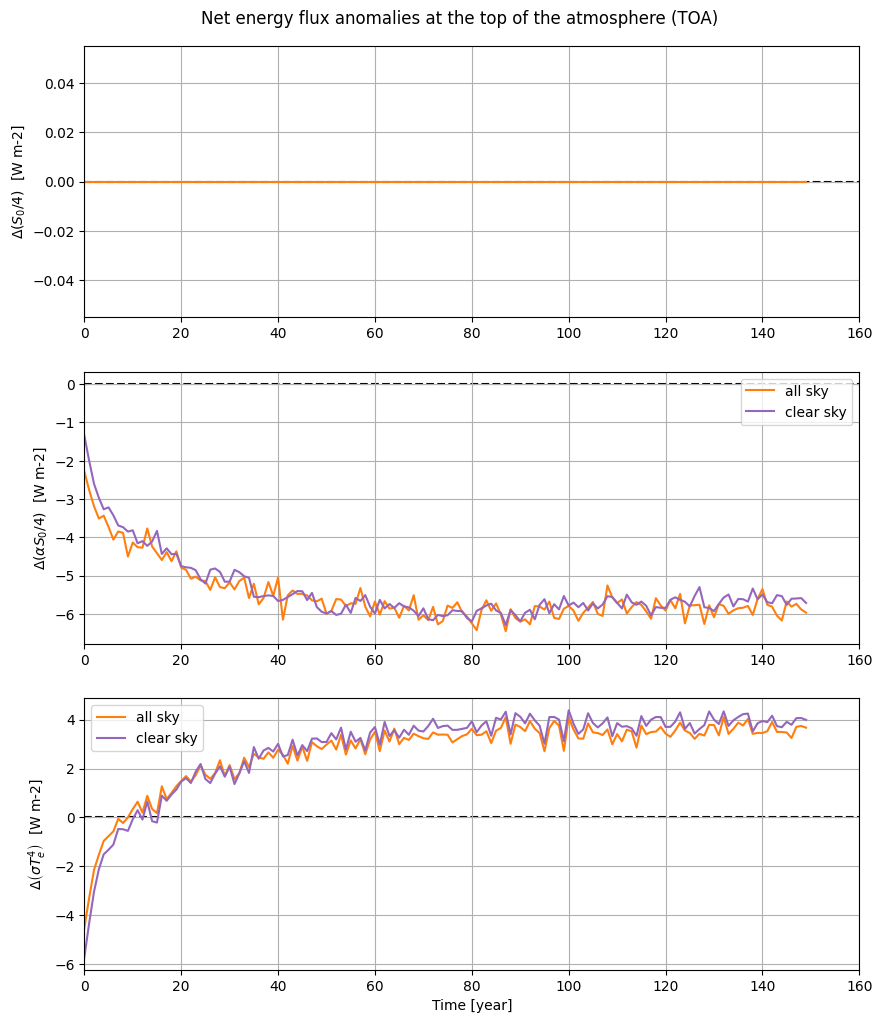

In [19]:
# plot temperature and energy anomalies
fig, axes = plt.subplots(3,1, figsize=(10, 12))

dRLUT     = (abrupt['rlut'] - piCtrl['rlut']).groupby('time.year').mean()
dRSUT     = (abrupt['rsut'] - piCtrl['rsut']).groupby('time.year').mean()
dRSDT     = (abrupt['rsdt'] - piCtrl['rsdt']).groupby('time.year').mean()

dRLUTCS   = (abrupt['rlutcs'] - piCtrl['rlutcs']).groupby('time.year').mean()
dRSUTCS   = (abrupt['rsutcs'] - piCtrl['rsutcs']).groupby('time.year').mean()

# dR
axes[0].plot( np.arange(len(dRSDT['year'])), dRSDT, c='tab:orange')
axes[1].plot( np.arange(len(dRSUT['year'])), dRSUT, c='tab:orange', label='all sky')
axes[2].plot( np.arange(len(dRLUT['year'])), dRLUT, c='tab:orange', label='all sky')

axes[1].plot( np.arange(len(dRSUTCS['year'])), dRSUTCS, c='tab:purple', label='clear sky')
axes[2].plot( np.arange(len(dRLUTCS['year'])), dRLUTCS, c='tab:purple', label='clear sky')

axes[0].set_ylabel(r'$\Delta \left(S_0/4\right)$  [W m-2]')
axes[1].set_ylabel(r'$\Delta \left(\alpha S_0/4\right)$  [W m-2]')
axes[2].set_ylabel(r'$\Delta \left(\sigma T_e^4\right)$  [W m-2]')

for ax in axes:
    ax.hlines(0,0,160, color="k", ls="--", alpha=1, zorder=-10)
    ax.grid(True)
    ax.set_xlim((0, 160))
    
    if ax == axes[-1]:
        ax.set_xlabel('Time [year]')
    
    if ax != axes[0]:
        ax.legend()


_ = fig.suptitle("Net energy flux anomalies at the top of the atmosphere (TOA)", y=0.91)

<font color="blue">

CNRM-CM6-1 simulates weak differences of energy flux anomalies (between _piControl_ and _abrupt-4xCO2_) indicating that the cloud feedback is weak. However, it is important to note that clouds feedback is really sensitive to model configuration (resolution, cloud scheme, etc.) and a different conclusion could arise with another model. It is therefore important to use multi-model analysis.
    
Interestingly, the difference between all sky and clear sky variables are marked in both _piControl_ and _abrupt-4xCO2_ (not shown) but the response is similar. This shows that the change in radiative fluxes arise from another mechanisms, at least in CNRM-CM6-1. 

</font>

#### Question 10

We will now focus on the surface albedo feedback.

* _Using surface variables, propose one or several figures illustrating the albedo feedback._    

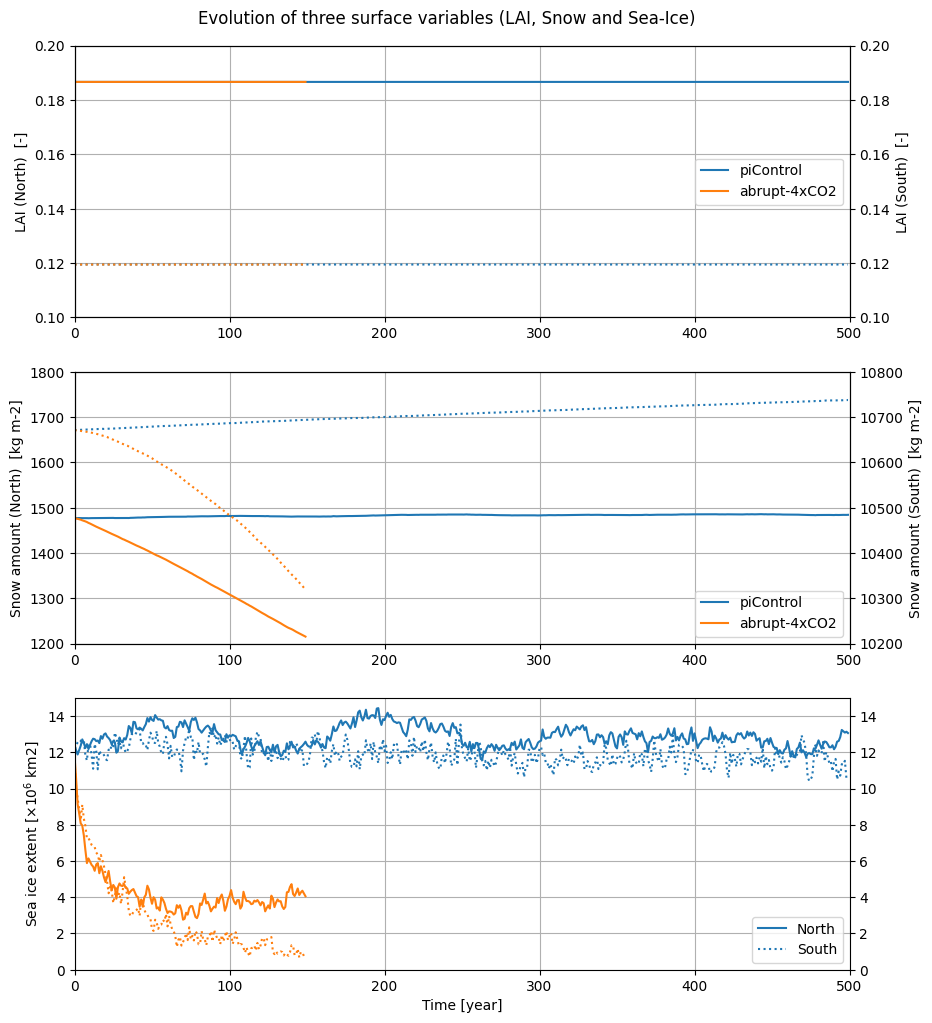

In [136]:
# plot temperature and energy anomalies
fig, axes = plt.subplots(3,1, figsize=(10, 12))


# piCtrl variables
lain     = (piCtrl['lain']).groupby('time.year').mean()
lais     = (piCtrl['lais']).groupby('time.year').mean()

snwn     = (piCtrl['snwn']).groupby('time.year').mean()
snws     = (piCtrl['snws']).groupby('time.year').mean()

siextn   = (piCtrl['siextentn']).groupby('time.year').mean()
siexts   = (piCtrl['siextents']).groupby('time.year').mean()

# abrupt variables
lain_a   = (abrupt['lain']).groupby('time.year').mean()
lais_a   = (abrupt['lais']).groupby('time.year').mean()

snwn_a   = (abrupt['snwn']).groupby('time.year').mean()
snws_a   = (abrupt['snws']).groupby('time.year').mean()

siextn_a = (abrupt['siextentn']).groupby('time.year').mean()
siexts_a = (abrupt['siextents']).groupby('time.year').mean()


# LAI
axes[0].plot( lain['year']-1850  , lain,   c='tab:blue',   ls='-' , label='piControl')
axes[0].plot( lain_a['year']-1850, lain_a, c='tab:orange', ls='-' , label='abrupt-4xCO2')
axes[0].legend(loc=5)

twinx_0 = axes[0].twinx()
twinx_0.plot( lais['year']-1850,   lais,   c='tab:blue',   ls=':')
twinx_0.plot( lais_a['year']-1850, lais_a, c='tab:orange', ls=':')

axes[0].set_ylim((0.1, 0.2))
twinx_0.set_ylim((0.1, 0.2))

axes[0].set_ylabel(r'LAI (North)  [-]')
twinx_0.set_ylabel(r'LAI (South)  [-]')


# Snow
axes[1].plot( snwn['year']-1850,   snwn,   c='tab:blue',   ls='-',  label='piControl')
axes[1].plot( snwn_a['year']-1850, snwn_a, c='tab:orange', ls='-' , label='abrupt-4xCO2')
axes[1].legend(loc=4)

twinx_1 = axes[1].twinx()
twinx_1.plot( snws['year']-1850,   snws,   c='tab:blue',   ls=':')
twinx_1.plot( snws_a['year']-1850, snws_a, c='tab:orange', ls=':')

axes[1].set_ylim((1200,  1800))
twinx_1.set_ylim((10200, 10800))

axes[1].set_ylabel(r'Snow amount (North)  [kg m-2]')
twinx_1.set_ylabel(r'Snow amount (South)  [kg m-2]')


# Sea ice
axes[2].plot( siextn['year']-1850, siextn, c='tab:blue', ls='-',  label='North')
axes[2].plot( siexts['year']-1850, siexts, c='tab:blue', ls=':', label='South')

axes[2].plot( siextn_a['year']-1850, siextn_a, c='tab:orange', ls='-')
axes[2].plot( siexts_a['year']-1850, siexts_a, c='tab:orange', ls=':')

axes[2].set_ylim((0, 15))
axes[2].set_ylabel(r'Sea ice extent [$\times 10^6$ km2]')

axes[2].yaxis.set_ticks_position('both')
axes[2].tick_params(labelright=True)
axes[2].legend()


for ax in axes:   
    ax.grid(True)    
    ax.set_xlim((0, 500))
    
    if ax == axes[-1]:
        ax.set_xlabel('Time [year]')
        

_ = fig.suptitle("Evolution of three surface variables (LAI, Snow and Sea-Ice) ", y=0.91)

<font color="blue">

Here we have plotted three different metrics showing surface changes during the two experiments. 
Each metric is decomposed into a northern and southern hemisphere value.

  - __Leaf area index__ (LAI) is a variable that represent the surface of vegetation per unit of area at the ground. Note that since vegetation occupies a 3D space, the LAI ratio can be greater than 1 (0 is a desert or urban area while 6 is highly dense forest such as tropical forests). In our simulations, the LAI metrics is constant and is not altered by the increase in CO$_2$ concentration (at least at the global scale). It is worth noting that the model used here does not represent the carbon cycle and the forest expansion is perhaps limited.   
    
    
  - As expected, most of the differences are found for the cryosphere (__snow amount__ and __sea_ice__). In particular, the sea ice exhibits a large retreat in both hemisphere in the forcing experiment. It is interesting to note that the sea-ice timeseries seems well correlated to the evolution of the upward shortwave radiation showing that it likely drives this change. One can note that, sea-ice extents are approximately similar in both hemisphere, but the northern ice shelf stabilize at a value twice than that of the southern. Conversely, snow amount is ten times greater in the southern hemispere (mostly due to the presence of the Antarctic) but exhibits the largest loss (around 350 kg.m-2). In the north, the loss is linear and reaches 280 kg.m-2 at the end of the _abrupt-4xcO2_ simulation.

Here we have highlighted the well known surface albedo feedback, which is mainly driven by changes in the cryosphere. However, it should be noted that the impact of the cryosphere in a changing climate is not limited to the albedo but includes air-sea interaction, ocean circulation alteration, water-cycle, etc..
    

</font>

#### Question 11

* _Using the figures and results you have plotted, propose a method to quantify the relative effect of a feedback._ 

__Help:__ we can assume a pre-industrial surface albedo $\alpha_0 \sim 0.3$

In [175]:
# Here, we focus on the surface albedo feedback

# First, compute the change in alpha
alpha_0     = 0.3
solar_in    = float(piCtrl['rsdt'].mean())           # or 1368/4 
piCtrl_SWup = float(piCtrl['rsut'].mean())
abrupt_SWup = float(abrupt['rsut'][-12*50:].mean())

alpha_f  = alpha_0 + (abrupt_SWup-piCtrl_SWup) / solar_in

# Then, compute the effective sensitivity parameter lambda
coeff_a  = - solar_in * (alpha_f-alpha_0) / ecs

print(r"New global surface albedo = {:.2f}".format(alpha_f))
print(r"Effective surface albedo sensitivity parameter = {:.2f} [W.m-2.K-1]".format(coeff_a))

New global surface albedo = 0.28
Effective surface albedo sensitivity parameter = 0.56 [W.m-2.K-1]


<font color="blue">

In the previous sections, we have shown :
  - the radiative budget is affected by the forcing in a similar way for all-sky and clear-sky conditions, illustrating a weak impact of clouds
  - the incoming solar radiation is constant though the simulation for each experiment
    
As a consequence, all surface changes that alter the upward radiative flux can be consider in a change in the global $\alpha$ parameter, so that:
    $$\Delta(\alpha S_0/4) = (\alpha_f - \alpha_0) S_0/4 = \Delta \mathrm{LW}_\text{up}$$

This give the new climate albedo $\alpha_f$ under CO$_2$ forcing:
    $$\alpha_f = \alpha_0 + \Delta \mathrm{LW}_\text{up} \times 4/S_0 \approx 0.28$$
    
To quantify the contribution of the albedo feedback to the climate sensitivity, one can compute the effective response relative to albedo:
    $$ \lambda_\alpha = \frac{\partial R}{\partial \alpha}\frac{\partial \alpha}{\partial T_s} = - S_0/4 \frac{\partial \alpha}{\partial T_s}$$
    
Or by linearized the previous equaition: $\lambda_\alpha = -S_0/4 \frac{\Delta \alpha}{\Delta T_s} \approx 0.56 \;\mathrm{W m}^{-2} \mathrm{K}^{-1}$
    
This value is larger but in the range of the expected value (0.35 $\pm$ 0.25 W.m-2.K-1) but calculation here have been made with short forcing simulation, and errors could arise from the choice in the global equilibrated variable (such as the ECS).
</font>

#### Going further (optional)

In the previous sections, we have relate the Earth energy balance with physical and climate variables. 
However, they are still topics to explore if wanted. Among other:

* _For now, we have mainly explained the variation in the shortwave upward flux. What are the mechanisms that drive the upward longwave changes ?._
* _We have seen that the increase in surface temperature can drive a surface albedo feedback. Howeve, we have only made calculation using global integrated value. Finer analysing is often required to spatialize and understand where the changes occur._
* _There are plenty of variables that are simulated by general circulation models, you can ask fo any ideas or wishes that is able to satisfy your curiosity !_

## 4. Conclusion and discussion

We conclude the notebook by using output from another CMIP6 model (TODO)

#### Question 12

* _Compare some of the results you have obtained from CNRM-CM6-1 by computing similar metrics with the new experiments._ 

* _Comment on the difference and conclude the lecture_